# Klasifikasi Multikelas - Dokumentasi 3 Dataset

**Definisi:** target memiliki **lebih dari 2 kelas**, tetapi setiap data hanya masuk ke **satu** kelas.

| No | Dataset | Sumber |
|---|---|---|
| 1 | Estimation of Obesity Levels | UCI Machine Learning Repository (ID 544) |
| 2 | Dry Bean Dataset | UCI Machine Learning Repository (ID 602) |
| 3 | Fashion-MNIST | Zalando Research |

Ketiganya dimuat otomatis (butuh internet; Google Colab sudah cukup).

In [1]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, io, os
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 160)

def muat_csv(nama_file, **kw):
    """Baca CSV lokal; jika tidak ada dan berjalan di Colab, minta upload file."""
    if os.path.exists(nama_file):
        return pd.read_csv(nama_file, **kw)
    try:
        from google.colab import files
        print(f"Upload file: {nama_file}")
        up = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(up.values()))), **kw)
    except ImportError:
        raise FileNotFoundError(f"Letakkan {nama_file} di folder yang sama dengan notebook ini.")

def analisis_single_label(nama, y, nama_kelas=None):
    y = pd.Series(np.asarray(y).ravel()).reset_index(drop=True)
    vc = y.value_counts().sort_index()
    if nama_kelas is not None:
        vc.index = [nama_kelas.get(i, i) for i in vc.index]
    persen = (vc / vc.sum() * 100).round(2)
    tabel = pd.DataFrame({"Jumlah": vc, "Persentase (%)": persen})
    rin = {"Dataset": nama, "Jumlah Data": int(vc.sum()), "Jumlah Kelas": int(len(vc)),
           "Kelas Mayoritas (%)": float(persen.max()), "Kelas Minoritas (%)": float(persen.min()),
           "Imbalance Ratio": round(vc.max() / vc.min(), 2),
           "Tipe Terdeteksi": "Biner" if len(vc) == 2 else ("Multikelas" if len(vc) > 2 else "Satu kelas")}
    return tabel, rin

def analisis_multilabel(nama, Y, nama_label):
    Y = np.asarray(Y).astype(int); n, L = Y.shape; pb = Y.sum(axis=1); card = pb.mean()
    tabel = pd.DataFrame({"Jumlah": Y.sum(axis=0), "Persentase (%)": (Y.mean(axis=0) * 100).round(2)}, index=list(nama_label))
    rin = {"Dataset": nama, "Jumlah Data": n, "Jumlah Label": L,
           "Label Cardinality": round(card, 3), "Label Density": round(card / L, 3),
           "% Data 0 Label": round((pb == 0).mean() * 100, 2), "% Data 1 Label": round((pb == 1).mean() * 100, 2),
           "% Data >1 Label (Multilabel)": round((pb > 1).mean() * 100, 2), "Maks Label per Data": int(pb.max()),
           "Tipe Terdeteksi": "Multilabel" if (pb > 1).any() else "Bukan multilabel"}
    return tabel, rin

def plot_bar(ax, tabel, judul, horizontal=False):
    s = tabel["Persentase (%)"]
    (s.plot(kind="barh", ax=ax, color="steelblue") if horizontal else s.plot(kind="bar", ax=ax, color="steelblue"))
    ax.set_title(judul); (ax.set_xlabel if horizontal else ax.set_ylabel)("Persentase (%)")

## 1. Estimation of Obesity Levels
- **Sumber:** https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition
- **Pembuat:** Palechor & De la Hoz Manotas (2019), *Data in Brief*, DOI 10.1016/j.dib.2019.104344
- **Deskripsi:** kebiasaan makan dan kondisi fisik individu dari Meksiko, Peru, dan Kolombia
- **Jumlah data:** 2111 | **Fitur:** 16
- **Target:** `NObeyesdad` -> **7 kelas** (Insufficient Weight, Normal Weight, Overweight I & II, Obesity I, II, III)
- **Catatan penting:** 77% data dibuat sintetis dengan SMOTE, hanya 23% dari survei langsung. Cantumkan di laporan. Lisensi CC BY 4.0.

In [3]:
from ucimlrepo import fetch_ucirepo
obes = fetch_ucirepo(id=544)
X_obes, y_obes = obes.data.features, obes.data.targets
print(X_obes.shape); display(X_obes.head(3))
tab_obes, rin_obes = analisis_single_label("Obesity Levels", y_obes.iloc[:, 0])
display(tab_obes)

(2111, 16)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation


,Jumlah,Persentase (%)
Insufficient_Weight,272,12.88
Normal_Weight,287,13.60
Obesity_Type_I,351,16.63
Obesity_Type_II,297,14.07
Obesity_Type_III,324,15.35
Overweight_Level_I,290,13.74
Overweight_Level_II,290,13.74


## 2. Dry Bean Dataset
- **Sumber:** https://archive.ics.uci.edu/dataset/602/dry+bean+dataset
- **Pembuat:** Koklu & Ozkan (2020), *Computers and Electronics in Agriculture*, 174, 105507
- **Deskripsi:** citra 13.611 butir kacang kering diambil dengan kamera, lalu diekstrak menjadi fitur dimensi dan bentuk
- **Jumlah data:** 13611 | **Fitur:** 16
- **Target:** `Class` -> **7 kelas** (Seker, Barbunya, Bombay, Cali, Dermosan, Horoz, Sira). Lisensi CC BY 4.0.

In [4]:
bean = fetch_ucirepo(id=602)
X_bean, y_bean = bean.data.features, bean.data.targets
print(X_bean.shape); display(X_bean.head(3))
tab_bean, rin_bean = analisis_single_label("Dry Bean", y_bean.iloc[:, 0])
display(tab_bean)

(13611, 16)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066


,Jumlah,Persentase (%)
BARBUNYA,1322,9.71
BOMBAY,522,3.84
CALI,1630,11.98
DERMASON,3546,26.05
HOROZ,1928,14.17
SEKER,2027,14.89
SIRA,2636,19.37


## 3. Fashion-MNIST
- **Sumber:** https://github.com/zalandoresearch/fashion-mnist (juga di Kaggle: `zalando-research/fashionmnist`)
- **Pembuat:** Xiao, Rasul, Vollgraf (Zalando Research), 2017, arXiv:1708.07747
- **Deskripsi:** citra produk fashion Zalando, grayscale 28x28 piksel
- **Jumlah data:** 70.000 (60.000 latih + 10.000 uji) | **Fitur:** 784 piksel
- **Target:** 10 kategori pakaian -> **10 kelas**, seimbang (7.000 per kelas)
- Dimuat lewat Keras (tersedia di Google Colab). Hanya label yang dianalisis di sini.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 55s 2us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 9s 2us/step
Gambar latih: (60000, 28, 28) | uji: (10000, 28, 28)


,Jumlah,Persentase (%)
T-shirt/top,7000,10.0
Trouser,7000,10.0
Pullover,7000,10.0
Dress,7000,10.0
Coat,7000,10.0
Sandal,7000,10.0
Shirt,7000,10.0
Sneaker,7000,10.0
Bag,7000,10.0
Ankle boot,7000,10.0


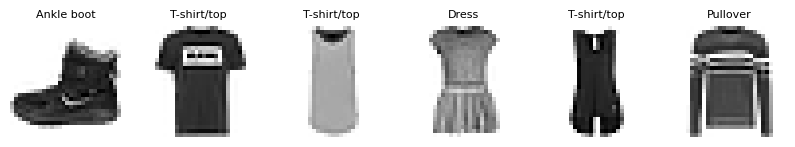

In [5]:
from tensorflow.keras.datasets import fashion_mnist
(Xtr, ytr), (Xte, yte) = fashion_mnist.load_data()
y_fash = np.concatenate([ytr, yte])
nama_fashion = {0:"T-shirt/top",1:"Trouser",2:"Pullover",3:"Dress",4:"Coat",
                5:"Sandal",6:"Shirt",7:"Sneaker",8:"Bag",9:"Ankle boot"}
print("Gambar latih:", Xtr.shape, "| uji:", Xte.shape)
tab_fash, rin_fash = analisis_single_label("Fashion-MNIST", y_fash, nama_fashion)
display(tab_fash)

fig, ax = plt.subplots(1, 6, figsize=(10, 2))
for a, img, l in zip(ax, Xtr[:6], ytr[:6]):
    a.imshow(img, cmap="gray_r"); a.set_title(nama_fashion[l], fontsize=8); a.axis("off")
plt.show()

## Perbandingan 3 Dataset Multikelas

,Jumlah Data,Jumlah Kelas,Kelas Mayoritas (%),Kelas Minoritas (%),Imbalance Ratio,Tipe Terdeteksi,Valid Multikelas?,Skor Keseimbangan (%)
Dataset,,,,,,,,
Obesity Levels,2111,7,16.63,12.88,1.29,Multikelas,True,90.2
Dry Bean,13611,7,26.05,3.84,6.79,Multikelas,True,26.9
Fashion-MNIST,70000,10,10.00,10.00,1.00,Multikelas,True,100.0


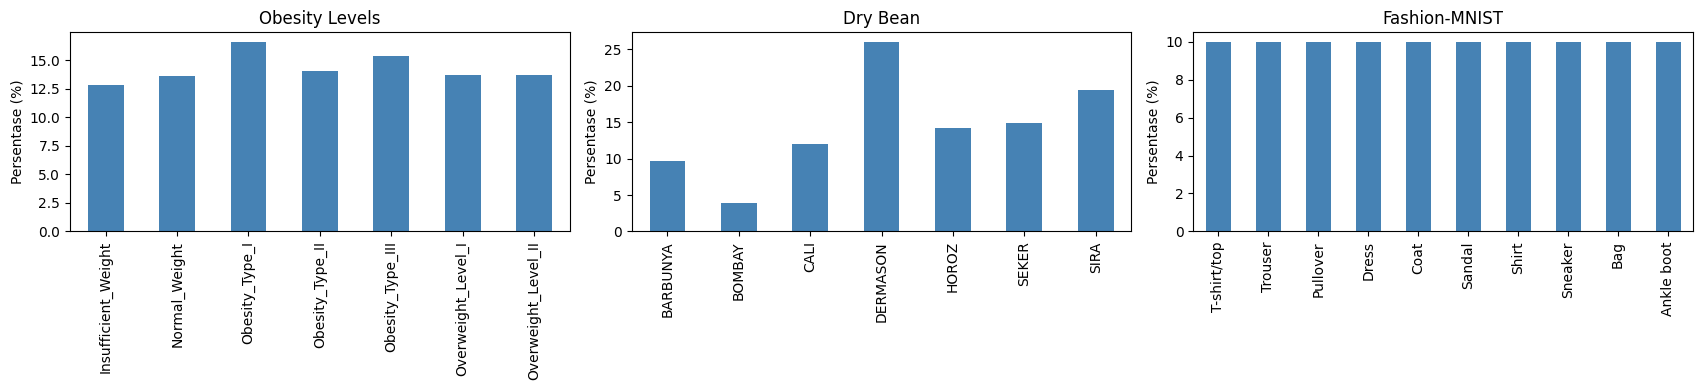

In [6]:
mc = pd.DataFrame([rin_obes, rin_bean, rin_fash]).set_index("Dataset")
mc["Valid Multikelas?"] = mc["Jumlah Kelas"] > 2
mc["Skor Keseimbangan (%)"] = (mc["Kelas Minoritas (%)"] / (100 / mc["Jumlah Kelas"]) * 100).round(1)
display(mc)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (t, n) in zip(ax, [(tab_obes, "Obesity Levels"), (tab_bean, "Dry Bean"), (tab_fash, "Fashion-MNIST")]):
    plot_bar(a, t, n)
plt.tight_layout(); plt.show()

In [7]:
valid = mc[mc["Valid Multikelas?"]]
print("Dataset valid sebagai multikelas (kelas > 2):", ", ".join(valid.index))
print("Paling seimbang :", valid["Skor Keseimbangan (%)"].idxmax())
print("Paling tidak seimbang :", valid["Skor Keseimbangan (%)"].idxmin())

Dataset valid sebagai multikelas (kelas > 2): Obesity Levels, Dry Bean, Fashion-MNIST
Paling seimbang : Fashion-MNIST
Paling tidak seimbang : Dry Bean


## Kesimpulan
(Isi setelah melihat output: ketiganya >2 kelas dengan satu label per data; bandingkan keseimbangan kelas berdasarkan persentase.)

## Daftar Pustaka
- Palechor, F. M., & De la Hoz Manotas, A. (2019). Dataset for estimation of obesity levels based on eating habits and physical condition in individuals from Colombia, Peru and Mexico. *Data in Brief*. https://doi.org/10.1016/j.dib.2019.104344. UCI: https://doi.org/10.24432/C5H31Z
- Koklu, M., & Ozkan, I. A. (2020). Multiclass classification of dry beans using computer vision and machine learning techniques. *Computers and Electronics in Agriculture, 174*, 105507. https://doi.org/10.1016/j.compag.2020.105507. UCI: https://doi.org/10.24432/C50S4B
- Xiao, H., Rasul, K., & Vollgraf, R. (2017). Fashion-MNIST: a novel image dataset for benchmarking machine learning algorithms. arXiv:1708.07747.

*(Tambahkan tanggal akses dan sesuaikan format sitasi dengan ketentuan dosen.)*